# Netflix Movies & TV Shows Data Analysis

### By: Yuganshi Bisen

---

## Project Objective

The objective of this project is to analyze Netflix's Movies and TV Shows dataset using Python. The project includes data cleaning, exploratory data analysis (EDA), and data visualization to discover meaningful insights about Netflix's content library.



# Libraries Used

In [128]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the Dataset

In [129]:
df = pd.read_csv("../data/netflix_titles.csv")

In [130]:
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


# Understanding the Dataset

Before performing any analysis, it is important to understand the structure of the dataset, including the number of rows, columns, data types, and missing values.

In [131]:
df.shape


(8807, 12)

In [132]:
df.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='str')

In [133]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 825.8 KB


In [134]:
df.isnull().sum()

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

In [135]:
df.duplicated().sum()

np.int64(0)

# Data Cleaning

The dataset contains missing values in several columns.

Cleaning steps performed:

- Filled missing values in Director, Cast and Country with "Unknown".
- Removed rows containing remaining missing values.


In [136]:
df["director"] = df["director"].fillna("Unknown")
df["cast"] = df["cast"].fillna("Unknown")
df["country"] = df["country"].fillna("Unknown")

In [137]:
df = df.dropna()

In [138]:
df.isnull().sum()

show_id         0
type            0
title           0
director        0
cast            0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
description     0
dtype: int64

# Exploratory Data Analysis (EDA)

The following analysis answers various business questions using the cleaned Netflix dataset.

## Business Question 1

### How many Movies and TV Shows are available on Netflix?

In [139]:
df["type"].value_counts()

type
Movie      6126
TV Show    2664
Name: count, dtype: int64

In [140]:
type_counts = df["type"].value_counts()
type_counts

type
Movie      6126
TV Show    2664
Name: count, dtype: int64

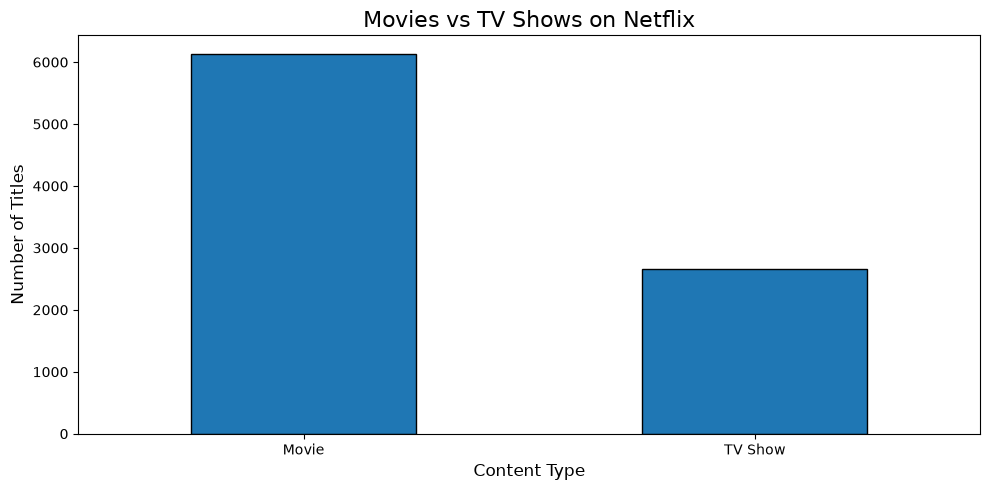

In [172]:
plt.figure(figsize=(10,5))

type_counts.plot(kind="bar",edgecolor="black")

plt.title("Movies vs TV Shows on Netflix", fontsize=16)
plt.xlabel("Content Type", fontsize=12)
plt.ylabel("Number of Titles", fontsize=12)

plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig("../images/movies_vs_tvshows.png", dpi=300)

plt.show()

The dataset contains significantly more Movies than TV Shows, indicating that Netflix's catalog is primarily focused on movies.

## Business Question 2

### Which countries contribute the most Netflix content?

In [142]:
country_counts = df["country"].value_counts().head(10)

country_counts


country
United States     2809
India              972
Unknown            829
United Kingdom     418
Japan              243
South Korea        199
Canada             181
Spain              145
France             124
Mexico             110
Name: count, dtype: int64

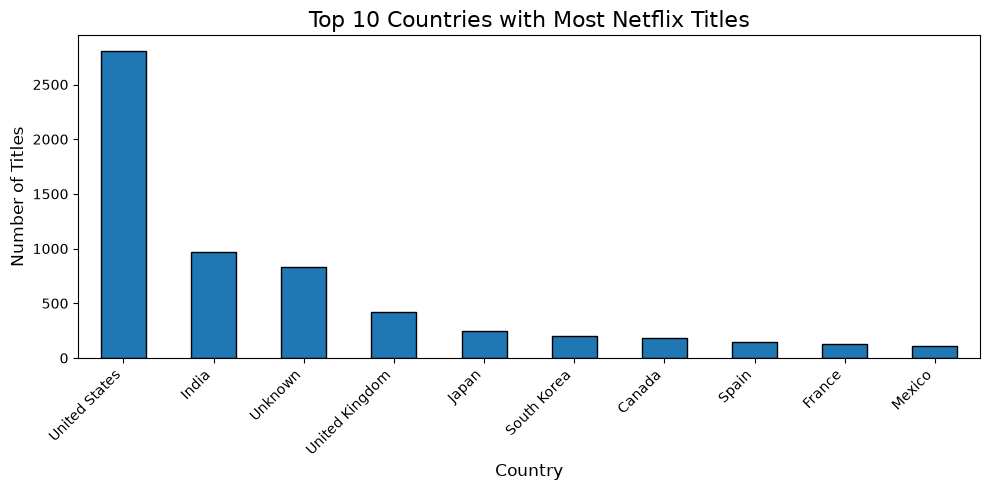

In [171]:
plt.figure(figsize=(10,5))

country_counts.plot(kind="bar", edgecolor="black")

plt.title("Top 10 Countries with Most Netflix Titles", fontsize=16)
plt.xlabel("Country", fontsize=12)
plt.ylabel("Number of Titles", fontsize=12)

plt.xticks(rotation=45, ha="right")

plt.tight_layout()

plt.savefig("../images/top_countries.png", dpi=300)

plt.show()

The United States has the highest number of Netflix titles, followed by India. This suggests that these countries are major contributors to Netflix's content library.

## Business Question 3

### How has Netflix's content grown over the years?

In [144]:
release_year_counts = df["release_year"].value_counts().sort_index()

year_counts

release_year
1925       1
1942       2
1943       3
1944       3
1945       4
        ... 
2017    1030
2018    1146
2019    1030
2020     953
2021     592
Name: count, Length: 74, dtype: int64

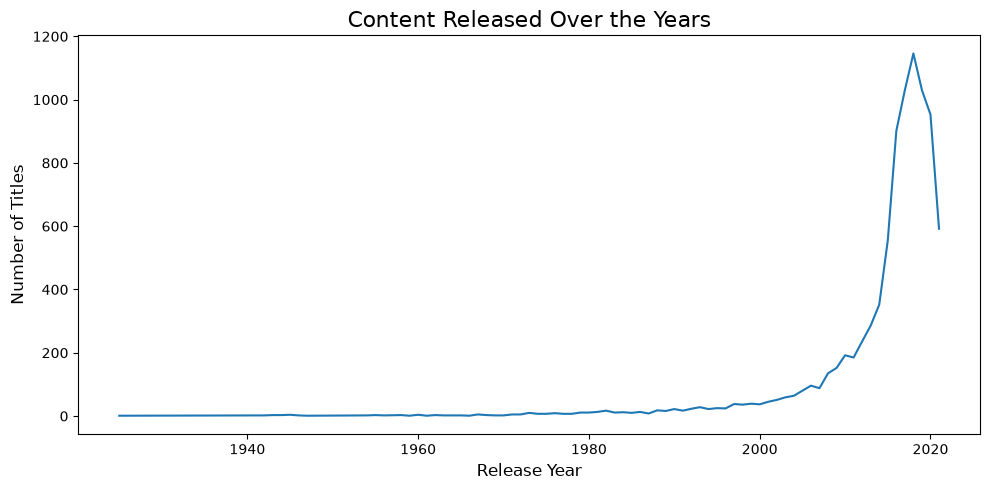

In [145]:
plt.figure(figsize=(10,5))

release_year_counts.plot(kind="line")

plt.title("Content Released Over the Years", fontsize=16)
plt.xlabel("Release Year", fontsize=12)
plt.ylabel("Number of Titles", fontsize=12)

plt.tight_layout()

plt.savefig("../images/release_year_trend.png", dpi=300)

plt.show()

The number of titles released on Netflix increased rapidly after 2015, getting its' peak in 2020 ,indicating significant expansion of the platform's content library.

## Business Question 4

### What are the most common content ratings on Netflix?

In [146]:
rating_counts = df["rating"].value_counts()

rating_counts

rating
TV-MA       3205
TV-14       2157
TV-PG        861
R            799
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64

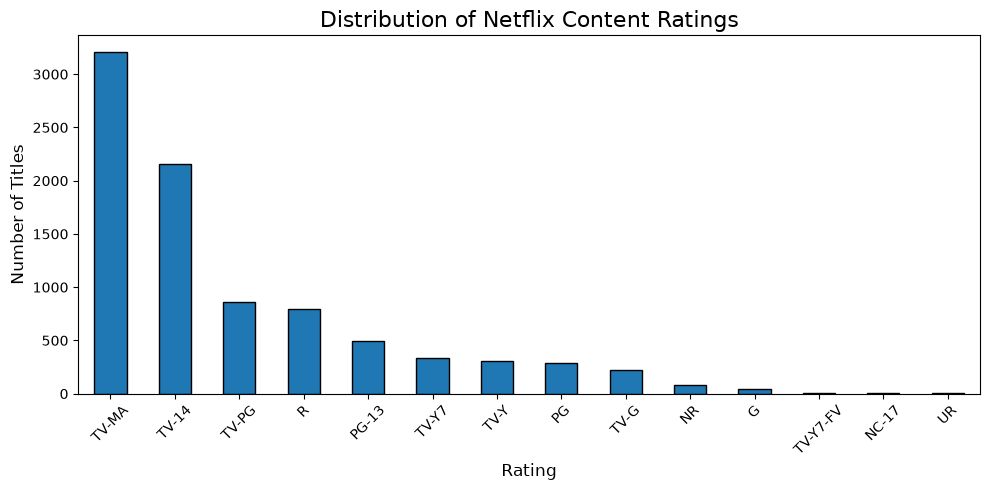

In [170]:
plt.figure(figsize=(10,5))

rating_counts.plot(kind="bar", edgecolor="black")

plt.title("Distribution of Netflix Content Ratings", fontsize=16)
plt.xlabel("Rating", fontsize=12)
plt.ylabel("Number of Titles", fontsize=12)

plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig("../images/ratings_distribution.png", dpi=300)

plt.show()

TV-MA is the most common content rating on Netflix, indicating that a large portion of Netflix's catalog is intended for mature audiences.

## Business Question 5

### Which genres are the most popular?

In [148]:
genre_counts = df["listed_in"].value_counts().head(10)

genre_counts



listed_in
Dramas, International Movies                        362
Documentaries                                       359
Stand-Up Comedy                                     334
Comedies, Dramas, International Movies              274
Dramas, Independent Movies, International Movies    252
Kids' TV                                            219
Children & Family Movies                            215
Children & Family Movies, Comedies                  201
Documentaries, International Movies                 186
Dramas, International Movies, Romantic Movies       180
Name: count, dtype: int64

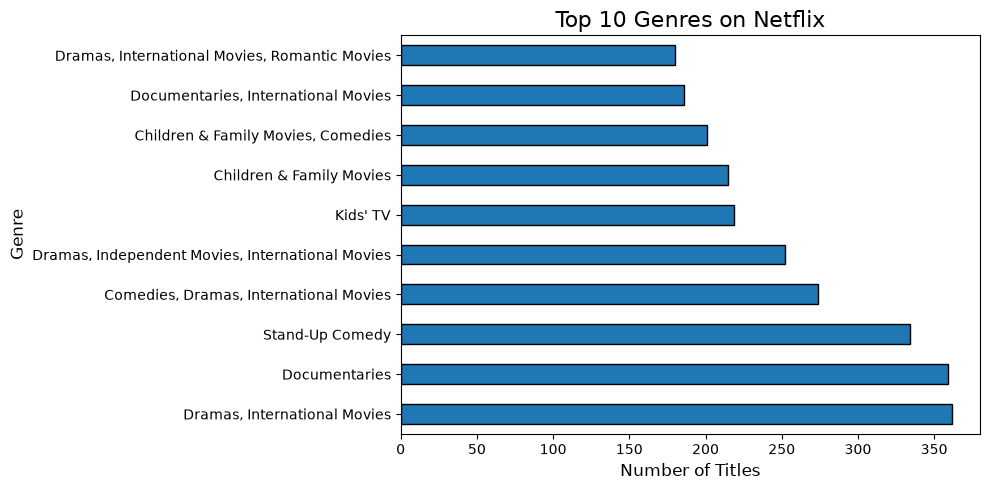

In [173]:
plt.figure(figsize=(10,5))

genre_counts.plot(kind="barh", edgecolor="black")

plt.title("Top 10 Genres on Netflix", fontsize=16)
plt.xlabel("Number of Titles", fontsize=12)
plt.ylabel("Genre", fontsize=12)

plt.tight_layout()

plt.savefig("../images/top_genres.png", dpi=300)

plt.show()

International Movies, Dramas, and Documentaries are among the most common genres on Netflix.

## Business Question 6

### Who are the top directors on Netflix?

In [150]:
director_counts = df[df["director"] != "Unknown"]["director"].value_counts().head(10)

director_counts

director
Rajiv Chilaka             19
Raúl Campos, Jan Suter    18
Suhas Kadav               16
Marcus Raboy              16
Jay Karas                 14
Cathy Garcia-Molina       13
Youssef Chahine           12
Martin Scorsese           12
Jay Chapman               12
Steven Spielberg          11
Name: count, dtype: int64

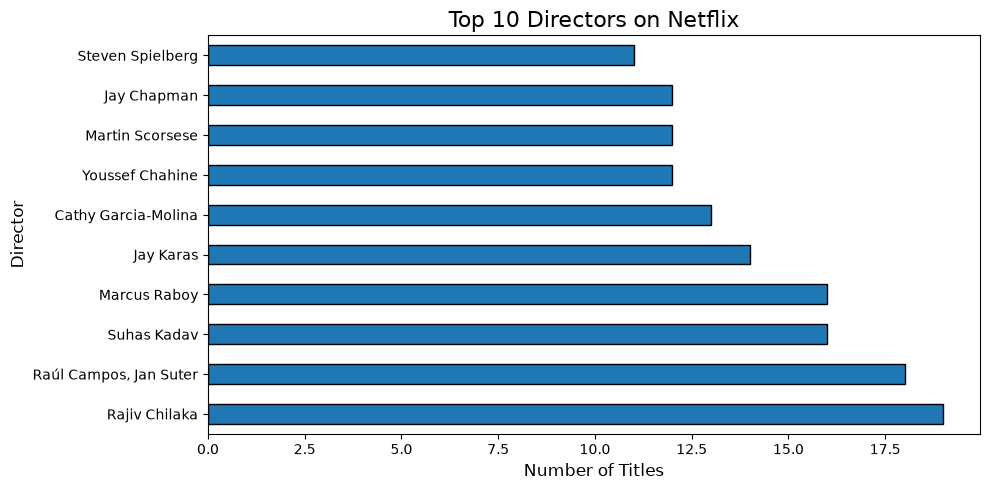

In [174]:
plt.figure(figsize=(10,5))

director_counts.plot(kind="barh", edgecolor="black")

plt.title("Top 10 Directors on Netflix", fontsize=16)
plt.xlabel("Number of Titles", fontsize=12)
plt.ylabel("Director", fontsize=12)

plt.tight_layout()

plt.savefig("../images/top_directors.png", dpi=300)

plt.show()

Rajiv Chilaka appears among the directors with the highest number of titles in the dataset.

## Business Question 7

### What is the distribution of movie durations?

In [152]:
movies = df[df["type"] == "Movie"].copy()

In [153]:
movies["duration_min"] = (
    movies["duration"]
    .str.replace(" min", "", regex=False)
    .astype(int)
)

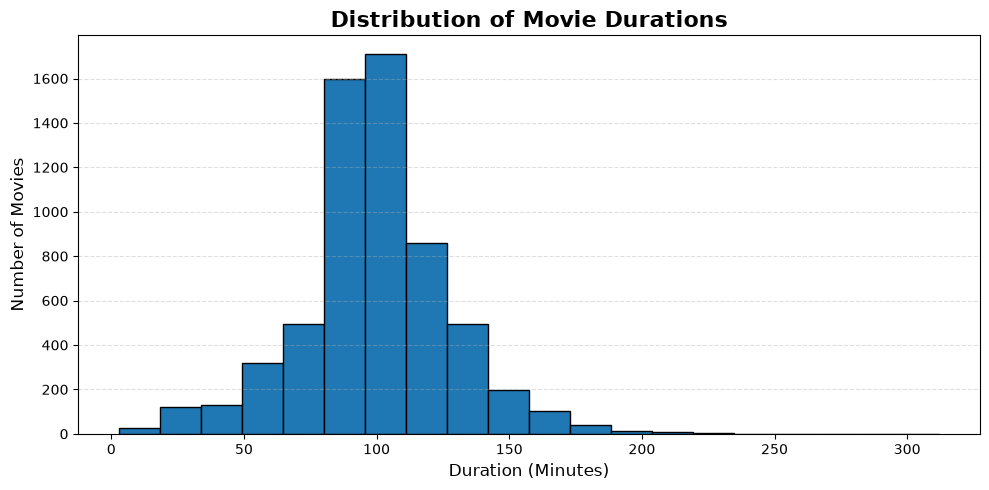

In [168]:
plt.figure(figsize=(10,5))

movies["duration_min"].plot(
    kind="hist",
    bins=20,
    edgecolor="black"
)

plt.title("Distribution of Movie Durations", fontsize=16, fontweight="bold")
plt.xlabel("Duration (Minutes)", fontsize=12)
plt.ylabel("Number of Movies", fontsize=12)

plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

plt.savefig("../images/movie_duration_distribution.png", dpi=300)

plt.show()

Most Netflix movies have a duration between 80 and 120 minutes

## Business Question 8

### In which years was the most content added to Netflix?

In [155]:
df["date_added"] = df["date_added"].str.strip()

In [156]:
df["date_added"] = pd.to_datetime(df["date_added"])

In [157]:
df["added_year"] = df["date_added"].dt.year

In [158]:
added_year_counts = df["added_year"].value_counts().sort_index()

added_year_counts

added_year
2008       2
2009       2
2010       1
2011      13
2012       3
2013      11
2014      24
2015      82
2016     426
2017    1185
2018    1648
2019    2016
2020    1879
2021    1498
Name: count, dtype: int64

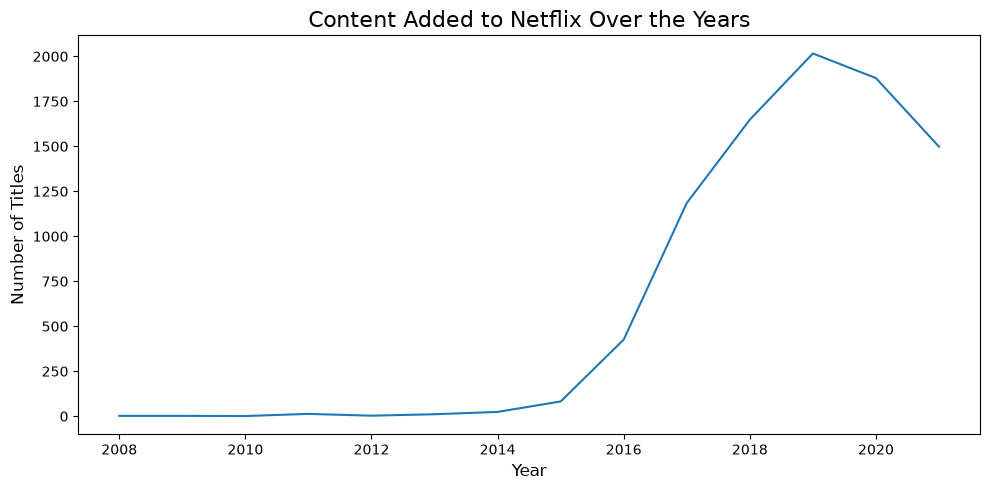

In [159]:
plt.figure(figsize=(10,5))

added_year_counts.plot(kind="line")

plt.title("Content Added to Netflix Over the Years", fontsize=16)
plt.xlabel("Year", fontsize=12)
plt.ylabel("Number of Titles", fontsize=12)

plt.tight_layout()

plt.savefig("../images/content_added_over_years.png", dpi=300)

plt.show()

Netflix experienced rapid growth in content additions between 2016 and 2020.

## Business Question 9

### Which release years have the highest number of titles on Netflix?

In [162]:
top_release_years = df["release_year"].value_counts().head(10)

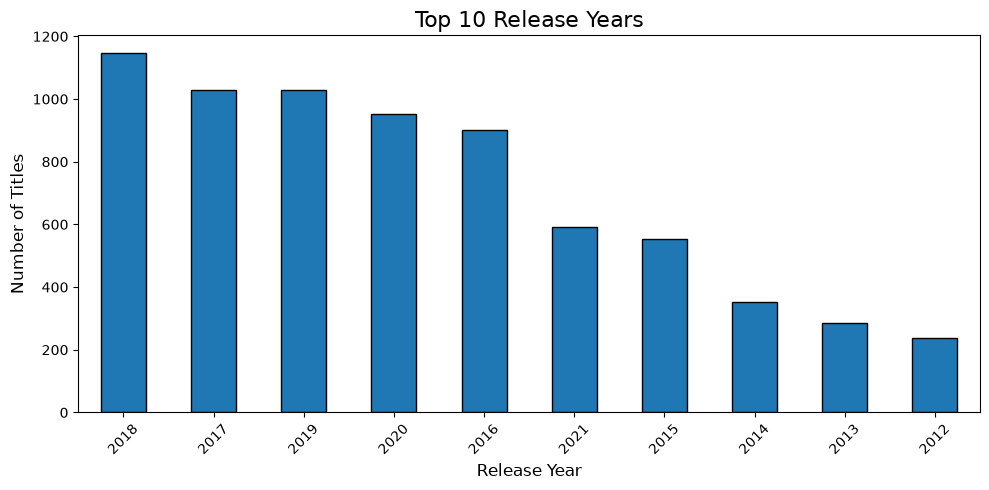

In [175]:
plt.figure(figsize=(10,5))

top_release_years.plot(kind="bar", edgecolor="black")

plt.title("Top 10 Release Years", fontsize=16)
plt.xlabel("Release Year", fontsize=12)
plt.ylabel("Number of Titles", fontsize=12)

plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig("../images/top_release_years.png", dpi=300)

plt.show()


- The majority of Netflix titles were released in recent years.
- This indicates that Netflix's content library is dominated by modern content.
- The platform focuses more on acquiring and producing recently released Movies and TV Shows than older titles.

## Business Question 10

### Which actors appear most frequently on Netflix?

In [36]:
cast_df = df.copy()

In [37]:
cast_df["cast"] = cast_df["cast"].str.split(", ")

In [38]:
cast_df = cast_df.explode("cast")

In [39]:
cast_df = cast_df[cast_df["cast"] != "Unknown"]

In [40]:
top_actors = cast_df["cast"].value_counts().head(10)

top_actors

cast
Anupam Kher         43
Shah Rukh Khan      35
Julie Tejwani       33
Naseeruddin Shah    32
Takahiro Sakurai    32
Rupa Bhimani        31
Akshay Kumar        30
Om Puri             30
Yuki Kaji           29
Amitabh Bachchan    28
Name: count, dtype: int64

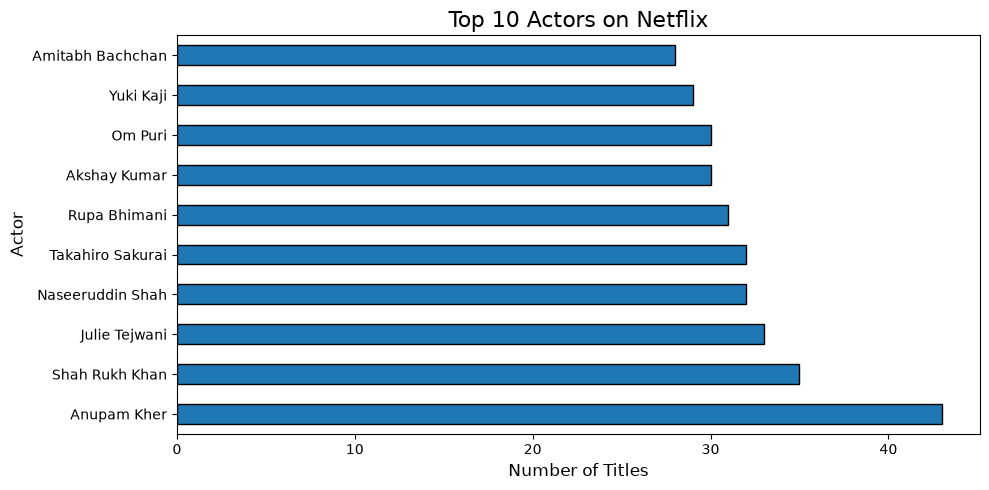

In [176]:
plt.figure(figsize=(10,5))

top_actors.plot(kind="barh", edgecolor="black")

plt.title("Top 10 Actors on Netflix", fontsize=16)
plt.xlabel("Number of Titles", fontsize=12)
plt.ylabel("Actor", fontsize=12)

plt.tight_layout()

plt.savefig("../images/top_actors.png", dpi=300)

plt.show()

The analysis shows the actors who appear most frequently in the Netflix dataset. This indicates that these actors have collaborated on multiple Netflix titles or are featured in content that Netflix has licensed extensively.

## Business Question 11

### How has the number of TV Shows added to Netflix changed over the years?

In [44]:
# Create separate datasets for Movies and TV Shows
movies = df[df["type"] == "Movie"].copy()
tv_shows = df[df["type"] == "TV Show"].copy()

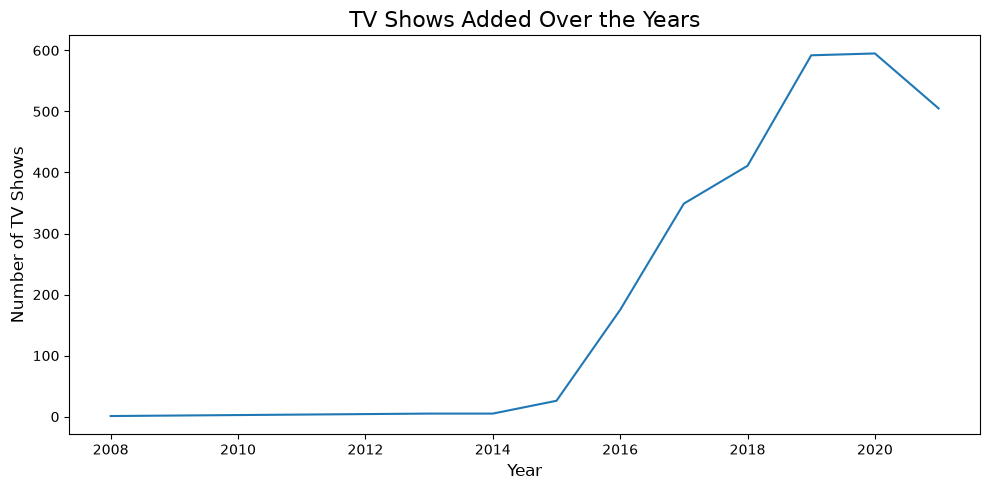

In [166]:
plt.figure(figsize=(10,5))

tv_added.plot(kind="line")

plt.title("TV Shows Added Over the Years", fontsize=16)
plt.xlabel("Year", fontsize=12)
plt.ylabel("Number of TV Shows", fontsize=12)

plt.tight_layout()

plt.savefig("../images/tv_shows_added.png", dpi=300)

plt.show()


- The number of TV Shows added to Netflix increased steadily after 2015.
- Netflix significantly expanded its TV Show catalog between 2016 and 2020.
- This trend reflects Netflix's increasing investment in original series and television content.